In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
DATA_PATH = "/kaggle/input/datasets/rukenmissonnier/manufacturing-data-for-polynomial-regression/manufacturing.csv"

df = pd.read_csv(DATA_PATH)

# Display first 5 rows
display(df.head())

# Dataset information
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

# Statistical summary
display(df.describe())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

,Temperature (°C),Pressure (kPa),Temperature x Pressure,Material Fusion Metric,Material Transformation Metric,Quality Rating
0,209.762701,8.050855,1688.769167,44522.217074,9.229576e+06,99.999971
1,243.037873,15.812068,3842.931469,63020.764997,1.435537e+07,99.985703
2,220.552675,7.843130,1729.823314,49125.950249,1.072839e+07,99.999758
3,208.976637,23.786089,4970.736918,57128.881547,9.125702e+06,99.999975
4,184.730960,15.797812,2918.345014,38068.201283,6.303792e+06,100.000000


Dataset Shape: (3957, 6)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3957 entries, 0 to 3956
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Temperature (°C)                3957 non-null   float64
 1   Pressure (kPa)                  3957 non-null   float64
 2   Temperature x Pressure          3957 non-null   float64
 3   Material Fusion Metric          3957 non-null   float64
 4   Material Transformation Metric  3957 non-null   float64
 5   Quality Rating                  3957 non-null   float64
dtypes: float64(6)
memory usage: 185.6 KB


,Temperature (°C),Pressure (kPa),Temperature x Pressure,Material Fusion Metric,Material Transformation Metric,Quality Rating
count,3957.000000,3957.000000,3957.000000,3957.000000,3.957000e+03,3957.000000
mean,200.034704,14.815558,2955.321308,48127.183128,1.003645e+07,96.260179
std,58.135717,5.772040,1458.224940,23812.213513,7.599356e+06,12.992262
min,100.014490,5.003008,513.706875,10156.971955,9.999462e+05,1.000000
25%,150.871296,9.692984,1798.247303,27626.929091,3.433810e+06,99.941129
50%,198.603371,14.832557,2678.277782,44611.452164,7.833390e+06,99.999997
75%,251.366552,19.749680,3929.058261,67805.443846,1.588251e+07,100.000000
max,299.992804,24.999132,7365.018714,103756.181544,2.699783e+07,100.000000



Missing Values:
Temperature (°C)                  0
Pressure (kPa)                    0
Temperature x Pressure            0
Material Fusion Metric            0
Material Transformation Metric    0
Quality Rating                    0
dtype: int64

Duplicate Rows: 0


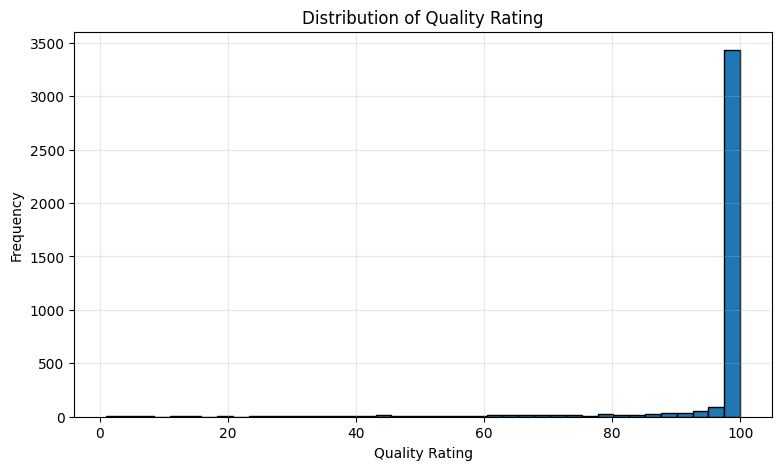

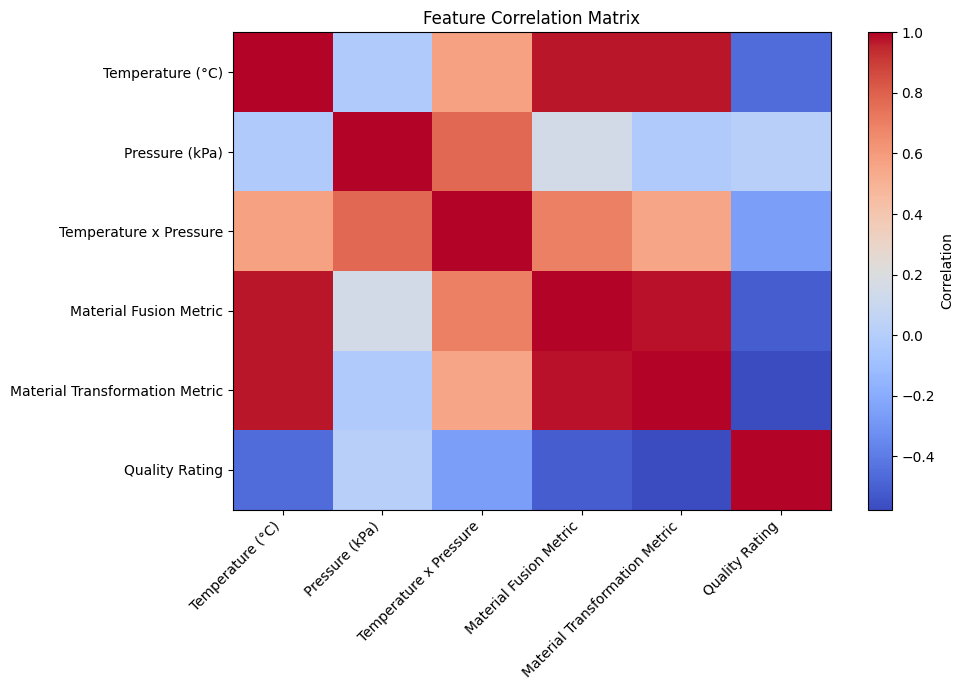

Quality Rating                    1.000000
Pressure (kPa)                    0.013129
Temperature x Pressure           -0.258474
Temperature (°C)                 -0.461279
Material Fusion Metric           -0.511972
Material Transformation Metric   -0.575756
Name: Quality Rating, dtype: float64

In [38]:
# Target distribution

plt.figure(figsize=(9, 5))
plt.hist(df["Quality Rating"], bins=40, edgecolor="black")

plt.title("Distribution of Quality Rating")
plt.xlabel("Quality Rating")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.show()


# Correlation matrix

correlation = df.corr()

plt.figure(figsize=(10, 7))
plt.imshow(correlation, cmap="coolwarm", aspect="auto")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

display(correlation["Quality Rating"].sort_values(ascending=False))

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Separate features and target
X = df.drop(columns=["Quality Rating"])
y = df["Quality Rating"].to_numpy()

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Generate polynomial features
poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Scale input features
X_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train_poly)
X_test_scaled = X_scaler.transform(X_test_poly)

# Scale target
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.reshape(-1, 1)
).ravel()

y_test_scaled = y_scaler.transform(
    y_test.reshape(-1, 1)
).ravel()

# Display results
print("Original training shape:", X_train.shape)
print("Polynomial training shape:", X_train_poly.shape)

print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])

print("Polynomial features:", X_train_scaled.shape[1])
print("Target shape:", y_train_scaled.shape)

print("\nGenerated Features:")
print(poly.get_feature_names_out(X.columns))

Original training shape: (3165, 5)
Polynomial training shape: (3165, 20)
Training samples: 3165
Testing samples: 792
Polynomial features: 20
Target shape: (3165,)

Generated Features:
['Temperature (°C)' 'Pressure (kPa)' 'Temperature x Pressure'
 'Material Fusion Metric' 'Material Transformation Metric'
 'Temperature (°C)^2' 'Temperature (°C) Pressure (kPa)'
 'Temperature (°C) Temperature x Pressure'
 'Temperature (°C) Material Fusion Metric'
 'Temperature (°C) Material Transformation Metric' 'Pressure (kPa)^2'
 'Pressure (kPa) Temperature x Pressure'
 'Pressure (kPa) Material Fusion Metric'
 'Pressure (kPa) Material Transformation Metric'
 'Temperature x Pressure^2'
 'Temperature x Pressure Material Fusion Metric'
 'Temperature x Pressure Material Transformation Metric'
 'Material Fusion Metric^2'
 'Material Fusion Metric Material Transformation Metric'
 'Material Transformation Metric^2']


In [40]:
class PolynomialRegression:

    def __init__(self, n_features):

        # Initialize weights and bias
        self.weights = np.zeros(n_features)
        self.bias = 0.0

    def predict(self, X):

        return X @ self.weights + self.bias

    def compute_loss(self, y_true, y_pred):

        errors = y_true - y_pred

        mse = np.mean(errors ** 2)

        return mse

    def compute_gradients(self, X, y_true, y_pred):

        n = len(y_true)

        errors = y_pred - y_true

        dw = (2 / n) * (X.T @ errors)

        db = (2 / n) * np.sum(errors)

        return dw, db

In [41]:
import time


def train_optimizer(
    optimizer,
    X,
    y,
    epochs=300,
    learning_rate=0.01,
    batch_size=32,
    momentum=0.9,
    beta=0.9,
    beta1=0.9,
    beta2=0.999,
    epsilon=1e-8
):

    n_samples, n_features = X.shape

    # Initialize a fresh model
    model = PolynomialRegression(n_features)

    # Momentum states
    velocity_w = np.zeros(n_features)
    velocity_b = 0.0

    # RMSProp states
    cache_w = np.zeros(n_features)
    cache_b = 0.0

    # Adam states
    m_w = np.zeros(n_features)
    m_b = 0.0

    v_w = np.zeros(n_features)
    v_b = 0.0

    losses = []
    update_step = 0

    start_time = time.perf_counter()

    for epoch in range(epochs):

        # Shuffle samples
        indices = np.random.permutation(n_samples)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        # Determine batch size
        if optimizer == "SGD":
            current_batch_size = 1

        elif optimizer in ["Mini-Batch GD", "Mini-Batch + Momentum"]:
            current_batch_size = batch_size

        else:
            current_batch_size = n_samples

        # Iterate over batches
        for start in range(0, n_samples, current_batch_size):

            end = min(start + current_batch_size, n_samples)

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            # Predictions
            y_pred = model.predict(X_batch)

            # Gradients
            dw, db = model.compute_gradients(
                X_batch,
                y_batch,
                y_pred
            )

            update_step += 1

            # 1. Gradient Descent
            if optimizer == "GD":

                model.weights -= learning_rate * dw
                model.bias -= learning_rate * db

            # 2. GD + Momentum
            elif optimizer == "GD + Momentum":

                velocity_w = momentum * velocity_w + dw
                velocity_b = momentum * velocity_b + db

                model.weights -= learning_rate * velocity_w
                model.bias -= learning_rate * velocity_b

            # 3. SGD
            elif optimizer == "SGD":

                model.weights -= learning_rate * dw
                model.bias -= learning_rate * db

            # 4. Mini-Batch GD
            elif optimizer == "Mini-Batch GD":

                model.weights -= learning_rate * dw
                model.bias -= learning_rate * db

            # 5. Mini-Batch GD + Momentum
            elif optimizer == "Mini-Batch + Momentum":

                velocity_w = momentum * velocity_w + dw
                velocity_b = momentum * velocity_b + db

                model.weights -= learning_rate * velocity_w
                model.bias -= learning_rate * velocity_b

            # 6. RMSProp
            elif optimizer == "RMSProp":

                cache_w = beta * cache_w + (1 - beta) * (dw ** 2)
                cache_b = beta * cache_b + (1 - beta) * (db ** 2)

                model.weights -= (
                    learning_rate * dw /
                    (np.sqrt(cache_w) + epsilon)
                )

                model.bias -= (
                    learning_rate * db /
                    (np.sqrt(cache_b) + epsilon)
                )

            # 7. Adam
            elif optimizer == "Adam":

                m_w = beta1 * m_w + (1 - beta1) * dw
                m_b = beta1 * m_b + (1 - beta1) * db

                v_w = beta2 * v_w + (1 - beta2) * (dw ** 2)
                v_b = beta2 * v_b + (1 - beta2) * (db ** 2)

                # Bias correction
                m_w_hat = m_w / (1 - beta1 ** update_step)
                m_b_hat = m_b / (1 - beta1 ** update_step)

                v_w_hat = v_w / (1 - beta2 ** update_step)
                v_b_hat = v_b / (1 - beta2 ** update_step)

                model.weights -= (
                    learning_rate * m_w_hat /
                    (np.sqrt(v_w_hat) + epsilon)
                )

                model.bias -= (
                    learning_rate * m_b_hat /
                    (np.sqrt(v_b_hat) + epsilon)
                )

        # Calculate full training loss after each epoch
        predictions = model.predict(X)

        epoch_loss = model.compute_loss(y, predictions)

        losses.append(epoch_loss)

    training_time = time.perf_counter() - start_time

    return model, losses, training_time

**Optimization Algorithms**

In [42]:
# 1. Gradient Descent (GD)

gd_model, gd_losses, gd_time = train_optimizer(
    optimizer="GD",
    X=X_train_scaled,
    y=y_train_scaled,
    epochs=300,
    learning_rate=0.01
)

print("Gradient Descent Results")
print("Initial MSE:", gd_losses[0])
print("Final MSE:", gd_losses[-1])
print("Training Time:", gd_time)

Gradient Descent Results
Initial MSE: 0.8548345834798734
Final MSE: 0.4261760192003001
Training Time: 0.06535520900069969


In [43]:
# 2. Gradient Descent with Momentum

gd_momentum_model, gd_momentum_losses, gd_momentum_time = train_optimizer(
    optimizer="GD + Momentum",
    X=X_train_scaled,
    y=y_train_scaled,
    epochs=300,
    learning_rate=0.01
)

print("GD with Momentum Results")
print("Initial MSE:", gd_momentum_losses[0])
print("Final MSE:", gd_momentum_losses[-1])
print("Training Time:", gd_momentum_time)

GD with Momentum Results
Initial MSE: 0.8548345834798735
Final MSE: 0.3493983543806293
Training Time: 0.06748434799919778


In [44]:
# 3. Stochastic Gradient Descent (SGD)

sgd_model, sgd_losses, sgd_time = train_optimizer(
    optimizer="SGD",
    X=X_train_scaled,
    y=y_train_scaled,
    epochs=300,
    learning_rate=0.001
)

print("SGD Results")
print("Initial MSE:", sgd_losses[0])
print("Final MSE:", sgd_losses[-1])
print("Training Time:", sgd_time)

SGD Results
Initial MSE: 0.44664017011182466
Final MSE: 0.23296775888359686
Training Time: 10.402315694998833


In [45]:
# 4. Mini-Batch Gradient Descent

mini_batch_model, mini_batch_losses, mini_batch_time = train_optimizer(
    optimizer="Mini-Batch GD",
    X=X_train_scaled,
    y=y_train_scaled,
    epochs=300,
    learning_rate=0.01,
    batch_size=32
)

print("Mini-Batch GD Results")
print("Initial MSE:", mini_batch_losses[0])
print("Final MSE:", mini_batch_losses[-1])
print("Training Time:", mini_batch_time)

Mini-Batch GD Results
Initial MSE: 0.528690554026372
Final MSE: 0.24766932135786518
Training Time: 0.3835523509987979


In [46]:
# 5. Mini-Batch Gradient Descent with Momentum

mini_batch_momentum_model, mini_batch_momentum_losses, mini_batch_momentum_time = train_optimizer(
    optimizer="Mini-Batch + Momentum",
    X=X_train_scaled,
    y=y_train_scaled,
    epochs=300,
    learning_rate=0.01,
    batch_size=32
)

print("Mini-Batch GD with Momentum Results")
print("Initial MSE:", mini_batch_momentum_losses[0])
print("Final MSE:", mini_batch_momentum_losses[-1])
print("Training Time:", mini_batch_momentum_time)

Mini-Batch GD with Momentum Results
Initial MSE: 0.4283546152447395
Final MSE: 0.2135776881950404
Training Time: 0.46528917999967234


In [47]:
# 6. RMSProp Optimizer

rmsprop_model, rmsprop_losses, rmsprop_time = train_optimizer(
    optimizer="RMSProp",
    X=X_train_scaled,
    y=y_train_scaled,
    epochs=300,
    learning_rate=0.001
)

print("RMSProp Results")
print("Initial MSE:", rmsprop_losses[0])
print("Final MSE:", rmsprop_losses[-1])
print("Training Time:", rmsprop_time)

RMSProp Results
Initial MSE: 0.9499742851090778
Final MSE: 0.44521869087982635
Training Time: 0.08252429799904348


In [48]:
# 7. Adam Optimizer

adam_model, adam_losses, adam_time = train_optimizer(
    optimizer="Adam",
    X=X_train_scaled,
    y=y_train_scaled,
    epochs=300,
    learning_rate=0.01
)

print("Adam Results")
print("Initial MSE:", adam_losses[0])
print("Final MSE:", adam_losses[-1])
print("Training Time:", adam_time)

Adam Results
Initial MSE: 0.8586316533935393
Final MSE: 0.37639525556295284
Training Time: 0.07159447800040653


In [49]:
# Summary of all optimizer experiments

all_models = {
    "GD": (gd_model, gd_losses, gd_time),
    "GD + Momentum": (gd_momentum_model, gd_momentum_losses, gd_momentum_time),
    "SGD": (sgd_model, sgd_losses, sgd_time),
    "Mini-Batch GD": (mini_batch_model, mini_batch_losses, mini_batch_time),
    "Mini-Batch GD + Momentum": (
        mini_batch_momentum_model,
        mini_batch_momentum_losses,
        mini_batch_momentum_time
    ),
    "RMSProp": (rmsprop_model, rmsprop_losses, rmsprop_time),
    "Adam": (adam_model, adam_losses, adam_time)
}

training_results = []

for name, (model, losses, elapsed) in all_models.items():

    training_results.append({
        "Optimizer": name,
        "Final Training MSE": losses[-1],
        "Training Time (seconds)": elapsed
    })

training_results_df = pd.DataFrame(training_results)

display(
    training_results_df.sort_values("Final Training MSE")
)

,Optimizer,Final Training MSE,Training Time (seconds)
4,Mini-Batch GD + Momentum,0.213578,0.465289
2,SGD,0.232968,10.402316
3,Mini-Batch GD,0.247669,0.383552
1,GD + Momentum,0.349398,0.067484
6,Adam,0.376395,0.071594
0,GD,0.426176,0.065355
5,RMSProp,0.445219,0.082524


In [50]:
# Evaluate all optimizers on the test set

test_results = []

for name, (model, losses, elapsed) in all_models.items():

    # Predict using test data
    predictions_scaled = model.predict(X_test_scaled)

    # Convert predictions back to original scale
    predictions = y_scaler.inverse_transform(
        predictions_scaled.reshape(-1, 1)
    ).ravel()

    # Calculate errors
    errors = y_test - predictions

    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)

    test_results.append({
        "Optimizer": name,
        "Test MSE": mse,
        "Test RMSE": rmse
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.sort_values("Test RMSE")
)

,Optimizer,Test MSE,Test RMSE
4,Mini-Batch GD + Momentum,45.717464,6.761469
2,SGD,47.270355,6.875344
3,Mini-Batch GD,49.135407,7.009665
1,GD + Momentum,71.057772,8.429577
6,Adam,75.841889,8.708725
0,GD,86.664638,9.309384
5,RMSProp,89.367327,9.453429


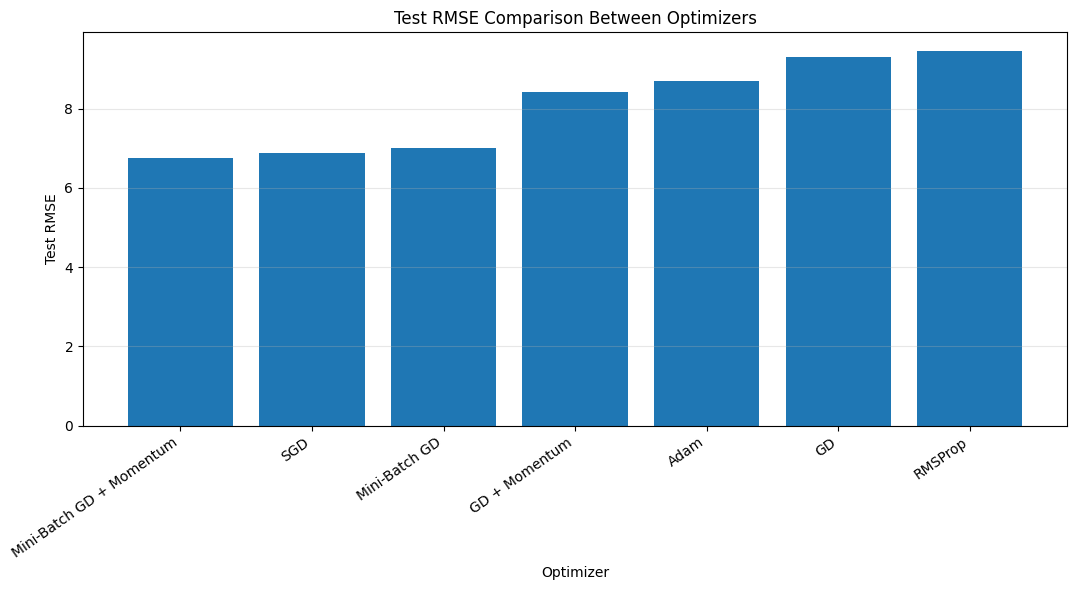

In [51]:
# Test RMSE Comparison

sorted_results = test_results_df.sort_values("Test RMSE")

plt.figure(figsize=(11, 6))

plt.bar(
    sorted_results["Optimizer"],
    sorted_results["Test RMSE"]
)

plt.title("Test RMSE Comparison Between Optimizers")
plt.xlabel("Optimizer")
plt.ylabel("Test RMSE")

plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

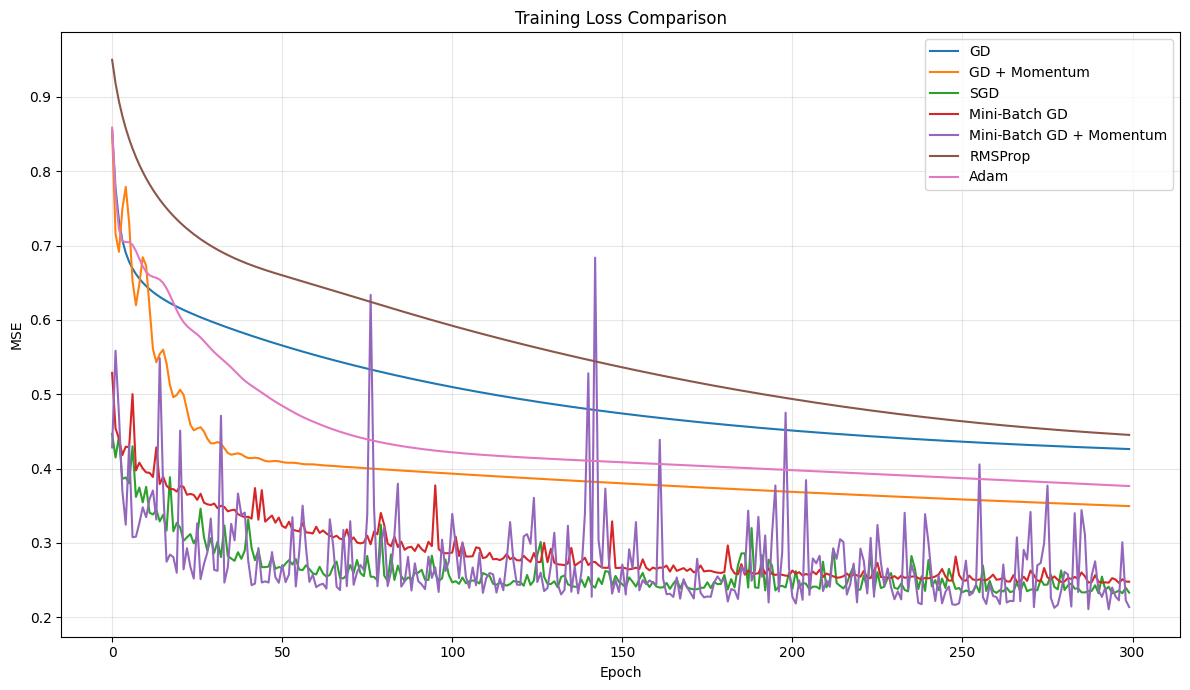

In [52]:
# Training Loss Comparison

plt.figure(figsize=(12, 7))

for name, (_, losses, _) in all_models.items():
    plt.plot(losses, label=name)

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("MSE")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [53]:
# Recalculate Training MSE on Original Scale

y_train_original = y_scaler.inverse_transform(
    y_train_scaled.reshape(-1, 1)
).ravel()

original_scale_results = []

for name, (model, losses, elapsed) in all_models.items():

    # Predict using training data
    predictions_scaled = model.predict(X_train_scaled)

    # Convert predictions to original scale
    predictions_original = y_scaler.inverse_transform(
        predictions_scaled.reshape(-1, 1)
    ).ravel()

    # Calculate MSE and RMSE
    errors = y_train_original - predictions_original

    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)

    original_scale_results.append({
        "Optimizer": name,
        "Training MSE": mse,
        "Training RMSE": rmse
    })

original_scale_df = pd.DataFrame(original_scale_results)

display(
    original_scale_df.sort_values("Training RMSE")
)

,Optimizer,Training MSE,Training RMSE
4,Mini-Batch GD + Momentum,34.142266,5.843138
2,SGD,37.241938,6.102617
3,Mini-Batch GD,39.592112,6.292226
1,GD + Momentum,55.854390,7.473579
6,Adam,60.170081,7.756938
0,GD,68.127972,8.253967
5,RMSProp,71.172110,8.436356


## Conclusion

In this experiment, five optimization algorithms were implemented and compared for Polynomial Regression: Gradient Descent (GD), Stochastic Gradient Descent (SGD), Mini-Batch Gradient Descent, RMSProp, and Adam. Momentum was also incorporated into GD and Mini-Batch GD to investigate its effect on optimization performance.

The experimental results showed that **Mini-Batch Gradient Descent with Momentum achieved the best test performance**, with an MSE of approximately 45.09 and an RMSE of approximately 6.71.

SGD achieved the second-best test performance, followed by Mini-Batch Gradient Descent. RMSProp recorded the highest test error among the evaluated optimizers under the selected hyperparameter settings.

The training loss curves also demonstrated differences in convergence behavior. Some optimizers showed smoother convergence, while others exhibited fluctuations during training.

Overall, the experiment demonstrates that optimizer performance depends on the optimization algorithm and its hyperparameter settings, including the learning rate, number of epochs, and batch size. The best optimizer in this experiment was Mini-Batch Gradient Descent with Momentum.